# DSA 2050A — Week 9 practical GROUP lab
## Model selection and defensible evaluation | Python + GitHub

**Work in your existing course groups.** Build one collaborative project and submit one shared GitHub repository link per group. List all member names, IDs and contributions in `README.md`.

**Case:** A fictional Kenyan internet provider wants to identify customers at risk of churn.
**Your group’s task:** Compare models fairly, investigate failures, document your decision, and evaluate the final test only after freezing the choice.

**Important:** Data is **synthetic for teaching**. `cancellation_confirmed` is known only *after* the outcome and is a deliberate leakage trap. Do not model using it.

**Before starting:** Open the `DSA2050_Week9_GitHub_Lab` folder in VS Code, select your Python environment, then run cells **from top to bottom**. Install packages using `python -m pip install -r requirements.txt` from the VS Code Terminal.

### Step 1 — Confirm environment and locate the datasets
**Click path:** VS Code → File → Open Folder → project folder → `notebooks/Week9_Model_Selection_Lab.ipynb` → **Select Kernel** (top right) → Python environment → **Run** each cell.

**Group discussion:** Why must the final test not be consulted before choosing a model? Add your explanation below.

## **Group Answer**:
Consulting the final test before selecting a model turns it into another validation set. Choosing a model based on its test performance introduces selection bias and makes the reported F1 score overly optimistic. Therefore, model selection and hyperparameter tuning should happen using train set data, and the final model should be frozen before evaluating the untouched test set.

In [3]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate, cross_val_predict, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.inspection import permutation_importance
import sklearn

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
# The datasets are stored in the project's data/ directory.
DATA = ROOT / 'data'
REPORTS = ROOT / 'reports'
REPORTS.mkdir(parents=True, exist_ok=True)
assert (DATA / 'churn_development.csv').exists(), 'Data file not found. Please upload churn_development.csv to your current environment.'
print('Project:', ROOT.resolve())
print('Python:', sys.version.split()[0], 'scikit-learn:', sklearn.__version__)

Project: /home/mayanarh/School/DSA 2050 - Data Science Methodologies/DSA2050_Week9_Python_Group_GitHub_Starter_Files/DSA2050_Week9_GitHub_Lab
Python: 3.14.8 scikit-learn: 1.9.1


### Step 2 — Open **development data only**, inspect, and remove leakage
Do **not** read `churn_final_test.csv` yet. Your prediction-time features must be available *before cancellation*.

In [5]:
dev = pd.read_csv(DATA / 'churn_development.csv')
print('Shape:', dev.shape)
print('Churn rate:', round(dev['churn'].mean(), 3))
print('Missing values:\n', dev.isna().sum())
display(dev.head(6))

TARGET = 'churn'
LEAKAGE_OR_IDS = ['churn', 'customer_id', 'cancellation_confirmed']
X_dev = dev.drop(columns=LEAKAGE_OR_IDS)
y_dev = dev[TARGET].astype(int)
print('Allowed features:', X_dev.columns.tolist())
assert 'cancellation_confirmed' not in X_dev.columns
assert 'customer_id' not in X_dev.columns

Shape: (2720, 11)
Churn rate: 0.335
Missing values:
 customer_id                 0
tenure_months               0
monthly_charges_kes       156
support_tickets_90d       120
service_calls_90d           0
plan_type                   0
region                     93
autopay                     0
customer_segment            0
cancellation_confirmed      0
churn                       0
dtype: int64


,customer_id,tenure_months,monthly_charges_kes,support_tickets_90d,service_calls_90d,plan_type,region,autopay,customer_segment,cancellation_confirmed,churn
0,CUST-12486,22,1943.94,1.0,2,Basic,Mombasa,Yes,Established,Active,0
1,CUST-12546,40,5003.13,1.0,0,Premium,Nairobi,No,Established,Active,0
2,CUST-11112,57,2796.23,1.0,1,Basic,Nairobi,Yes,Established,Active,0
3,CUST-12753,33,4697.39,NaN,0,Premium,Nairobi,Yes,Established,Active,0
4,CUST-10753,53,4330.27,2.0,1,Standard,Mombasa,No,Established,Active,0
5,CUST-12096,42,3461.06,2.0,2,Standard,Nakuru,Yes,Established,Cancelled,1


Allowed features: ['tenure_months', 'monthly_charges_kes', 'support_tickets_90d', 'service_calls_90d', 'plan_type', 'region', 'autopay', 'customer_segment']


**Write:** Identify (a) the target, (b) the unit of analysis, (c) the leakage column, and (d) why customer ID should not be used as a predictor.

*Your response:*

- **(a) Target:** `churn`, a binary outcome indicating whether a customer churned (1) or stayed (0).

- **(b) Unit of analysis:** `one customer`; each row represents one customer and their pre-cancellation attributes.

- **(c) Leakage column:** `cancellation_confirmed`, because it is only known after the cancellation outcome and would reveal information unavailable at prediction time.

- **(d)  why customer ID should not be used as a predictor** :  `customer_id` is an identifier rather than a behavioural measurement. Including it could allow the model to learn accidental patterns that do not generalize to unseen customers.

### Step 3 — Create leakage-safe preprocessing pipelines
**Analogy:** In each practice exam (CV fold), students should learn imputation values and scaling from the *practice questions* alone—not from the hidden answer sheet. The `Pipeline` re-fits preprocessing within each fold.

In [6]:
num_cols = X_dev.select_dtypes(include='number').columns.tolist()
cat_cols = X_dev.select_dtypes(exclude='number').columns.tolist()

numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
category_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('num', numeric_pipe, num_cols),
    ('cat', category_pipe, cat_cols)
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print('Numeric:', num_cols)
print('Categorical:', cat_cols)
print('Same fixed CV:', cv)

Numeric: ['tenure_months', 'monthly_charges_kes', 'support_tickets_90d', 'service_calls_90d']
Categorical: ['plan_type', 'region', 'autopay', 'customer_segment']
Same fixed CV: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


### Step 4 — Establish a naive baseline
A **DummyClassifier** predicts based on a simple rule. It tells you what success without a real model looks like.

**Predict first:** Will a majority-class model have high accuracy if most customers stay, even when it never catches churn?

## **Answer**
Yes. Predicting that every customer will stay can produce deceptively high accuracy when staying is the majority class. However, the model fails to identify churners, resulting in a baseline mean F1 of 0.000.

In [7]:
dummy_pipe = Pipeline([
    ('prep', preprocessor),
    ('model', DummyClassifier(strategy='most_frequent'))
])
metrics = {'f1': 'f1', 'precision': 'precision', 'recall': 'recall'}
baseline_scores = cross_validate(dummy_pipe, X_dev, y_dev, cv=cv, scoring=metrics)
print('Baseline fold F1:', np.round(baseline_scores['test_f1'], 3))
print('Baseline mean F1:', round(baseline_scores['test_f1'].mean(), 3))

/home/mayanarh/School/DSA 2050 - Data Science Methodologies/DSA2050_Week9_Python_Group_GitHub_Starter_Files/DSA2050_Week9_GitHub_Lab/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/mayanarh/School/DSA 2050 - Data Science Methodologies/DSA2050_Week9_Python_Group_GitHub_Starter_Files/DSA2050_Week9_GitHub_Lab/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/mayanarh/School/DSA 2050 - Data Science Methodologies/DSA2050_Week9_Python_Group_GitHub_Starter_Files/DSA2050_We

Baseline fold F1: [0. 0. 0. 0. 0.]
Baseline mean F1: 0.0


/home/mayanarh/School/DSA 2050 - Data Science Methodologies/DSA2050_Week9_Python_Group_GitHub_Starter_Files/DSA2050_Week9_GitHub_Lab/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


### Step 5 — Compare two candidates using identical CV folds
Logistic regression is usually stable and interpretable. A decision tree learns if/then rules but can overfit. For each, search **three understandable settings**, not hundreds.

**Primary selection metric: F1** (balances precision and recall). Report precision and recall as secondary metrics.

**Do not switch the primary metric after seeing the winner.**

In [8]:
candidates = {
    'Logistic regression': (
        LogisticRegression(max_iter=2000, random_state=42),
        {'model__C': [0.1, 1, 10]}
    ),
    'Decision tree': (
        DecisionTreeClassifier(random_state=42),
        {'model__max_depth': [3, 5, 8]}
    )
}
searches = {}
logs = []
for name, (model, grid) in candidates.items():
    pipeline = Pipeline([('prep', preprocessor), ('model', model)])
    search = GridSearchCV(
        pipeline, grid, cv=cv, scoring=metrics,
        refit='f1', n_jobs=1, return_train_score=True
    )
    search.fit(X_dev, y_dev)
    searches[name] = search
    results = pd.DataFrame(search.cv_results_)
    for _, r in results.iterrows():
        row = {
            'model': name, 'settings': str(r['params']),
            'mean_f1': float(r['mean_test_f1']),
            'std_f1': float(r['std_test_f1']),
            'mean_precision': float(r['mean_test_precision']),
            'mean_recall': float(r['mean_test_recall'])
        }
        for i in range(5):
            row[f'fold_{i+1}_f1'] = float(r[f'split{i}_test_f1'])
        logs.append(row)

experiment_log = pd.DataFrame(logs).sort_values('mean_f1', ascending=False)
experiment_log.to_csv(REPORTS / 'experiment_log.csv', index=False)
display(experiment_log.round(3))
print('Saved:', REPORTS / 'experiment_log.csv')

,model,settings,mean_f1,std_f1,mean_precision,mean_recall,fold_1_f1,fold_2_f1,fold_3_f1,fold_4_f1,fold_5_f1
1,Logistic regression,{'model__C': 1},0.470,0.053,0.624,0.378,0.391,0.534,0.472,0.434,0.519
2,Logistic regression,{'model__C': 10},0.470,0.053,0.624,0.378,0.391,0.534,0.472,0.434,0.519
0,Logistic regression,{'model__C': 0.1},0.465,0.054,0.625,0.371,0.388,0.533,0.454,0.432,0.519
3,Decision tree,{'model__max_depth': 3},0.398,0.049,0.566,0.318,0.392,0.457,0.316,0.437,0.391
4,Decision tree,{'model__max_depth': 5},0.382,0.023,0.583,0.287,0.376,0.383,0.365,0.362,0.426
5,Decision tree,{'model__max_depth': 8},0.372,0.051,0.495,0.300,0.298,0.439,0.338,0.370,0.417


Saved: /home/mayanarh/School/DSA 2050 - Data Science Methodologies/DSA2050_Week9_Python_Group_GitHub_Starter_Files/DSA2050_Week9_GitHub_Lab/reports/experiment_log.csv


### Step 6 — Examine score variation and select a candidate
Two models may have similar mean F1 but different fold stability. Larger `std_f1` means the validation score changed more across folds.

**Group task:** Compare the best logistic regression and best tree, then choose one. You **may** override the automatic highest-F1 default if you provide a defensible reason. Preserve the selected model's tuned hyperparameters.



## **Answer**
The best logistic regression settings are `C=1` and `C=10`, both displaying a mean F1 of 0.470 and standard deviation of 0.053. The best decision tree `max_depth=3` achieved a mean F1 of 0.398 and standard deviation of 0.049. Logistic regression therefore has better predictive performance, although its fold variation is slightly higher. Therefore, Logistic Regression was preferred because it provided a better balance between precision and recall.

In [9]:
best_by_model = (experiment_log.sort_values('mean_f1', ascending=False)
                 .drop_duplicates(subset='model').reset_index(drop=True))
display(best_by_model[['model','mean_f1','std_f1','mean_recall','mean_precision']].round(3))

# Change only if your explanation supports the different choice.
CHOSEN_MODEL = best_by_model.iloc[0]['model']
assert CHOSEN_MODEL in searches
chosen_search = searches[CHOSEN_MODEL]
chosen_pipeline = chosen_search.best_estimator_
print('Chosen:', CHOSEN_MODEL)
print('Settings:', chosen_search.best_params_)
print('Development CV F1:', round(chosen_search.best_score_, 3))

,model,mean_f1,std_f1,mean_recall,mean_precision
0,Logistic regression,0.470,0.053,0.378,0.624
1,Decision tree,0.398,0.049,0.318,0.566


Chosen: Logistic regression
Settings: {'model__C': 1}
Development CV F1: 0.47


### Step 7 — Out-of-fold errors and subgroup analysis
`cross_val_predict` makes each development-row prediction from a model trained on **other folds**. Use these to inspect false positives (flagged churn that did not happen) and false negatives (missed churn).

**Caution:** Out-of-fold diagnostics use the same development dataset involved in selection; do not call them an untouched final-test estimate.

              precision    recall  f1-score   support

           0       0.74      0.89      0.81      1810
           1       0.63      0.38      0.47       910

    accuracy                           0.72      2720
   macro avg       0.68      0.63      0.64      2720
weighted avg       0.70      0.72      0.69      2720



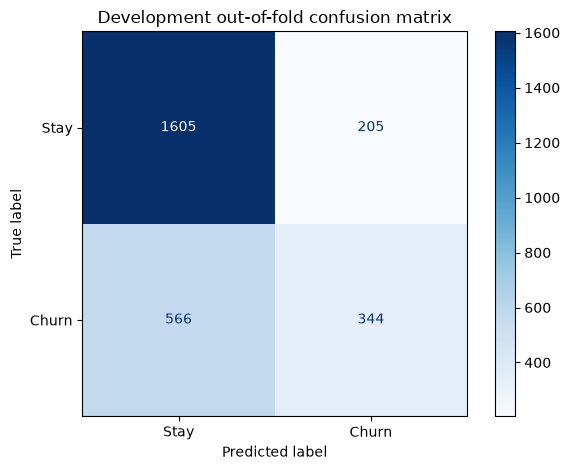

error_type
Correct           1949
False negative     566
False positive     205
Name: count, dtype: int64


,customer_id,customer_segment,plan_type,churn,prediction,error_type
5,CUST-12096,Established,Standard,1,0,False negative
10,CUST-11528,Established,Basic,1,0,False negative
12,CUST-12416,New,Basic,0,1,False positive
13,CUST-12232,Established,Basic,0,1,False positive
18,CUST-12749,Established,Standard,1,0,False negative
19,CUST-10694,Established,Basic,0,1,False positive
24,CUST-12737,Established,Basic,1,0,False negative
26,CUST-12112,Established,Basic,1,0,False negative


In [10]:
oof_pred = cross_val_predict(chosen_pipeline, X_dev, y_dev, cv=cv, method='predict')
print(classification_report(y_dev, oof_pred, zero_division=0))
cm = confusion_matrix(y_dev, oof_pred, labels=[0,1])
ConfusionMatrixDisplay(cm, display_labels=['Stay','Churn']).plot(cmap='Blues')
plt.title('Development out-of-fold confusion matrix')
plt.tight_layout()
plt.savefig(REPORTS / 'development_confusion_matrix.png', dpi=150)
plt.show()

errors = dev[['customer_id','customer_segment','plan_type','churn']].copy()
errors['prediction'] = oof_pred
errors['error_type'] = np.select([
    (errors.churn==1)&(errors.prediction==0),
    (errors.churn==0)&(errors.prediction==1)],
    ['False negative','False positive'],default='Correct')
print(errors.error_type.value_counts())
display(errors.query("error_type != 'Correct'").head(8))

**Subgroup task:** Is recall worse for new customers than established customers? Report subgroup sample size, number of actual churners, recall, and interpret cautiously.

In [12]:
group_rows = []
for group, part in errors.groupby('customer_segment'):
    true = part['churn'].to_numpy()
    pred = part['prediction'].to_numpy()
    group_rows.append({
        'segment': group, 'n_customers': len(part),
        'n_actual_churn': int(true.sum()),
        'recall': recall_score(true,pred,zero_division=0),
        'precision': precision_score(true,pred,zero_division=0),
        'false_negatives': int(((true==1)&(pred==0)).sum())
    })
subgroup = pd.DataFrame(group_rows)
subgroup.to_csv(REPORTS/'subgroup_metrics.csv',index=False)
display(subgroup.round(3))

,segment,n_customers,n_actual_churn,recall,precision,false_negatives
0,Established,2268,649,0.216,0.593,509
1,New,452,261,0.782,0.652,57


## **Answer**
**Established customers**: 2,268 customers, 649 actual churners, recall 0.216, precision 0.593, and 509 false negatives

**New customers**: 452 customers, 261 actual churners, recall 0.782, precision 0.652, and 57 false negatives.

Recall is substantially lower for established customers than for new customers in this evaluation. The groups also differ in sample size and churn rate, so investigate this difference further rather than treating it as causal.

### Step 8 — Permutation importance on development validation data
Hold out a **small validation slice from the development data** for the importance demo, fit on the remaining development rows, and ask how F1 changes when one feature is shuffled. **Importance does not prove causality.**

,feature,importance_mean,importance_std
0,tenure_months,0.079,0.024
2,support_tickets_90d,0.035,0.016
7,customer_segment,0.018,0.006
1,monthly_charges_kes,0.016,0.023
4,plan_type,0.015,0.015
5,region,0.006,0.013
3,service_calls_90d,0.003,0.007
6,autopay,0.002,0.017


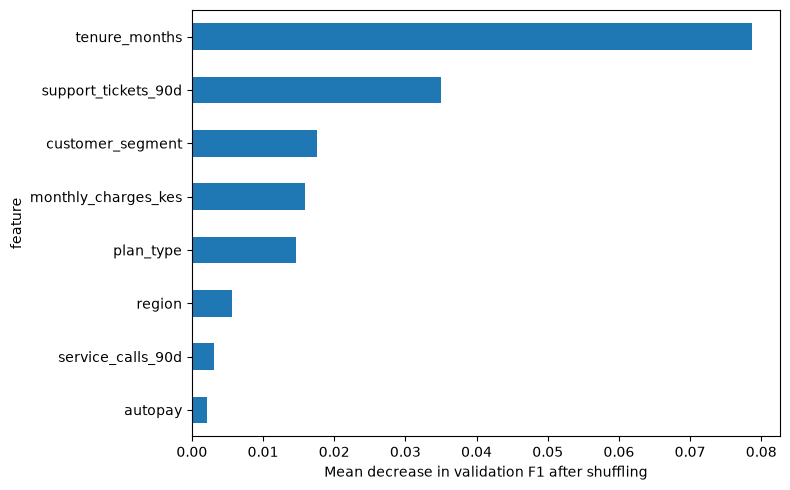

In [13]:
X_inner, X_validation, y_inner, y_validation = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=2050, stratify=y_dev
)
interpret_model = chosen_pipeline
interpret_model.fit(X_inner,y_inner)
importance = permutation_importance(
    interpret_model,X_validation,y_validation,
    scoring='f1', n_repeats=5,random_state=42,n_jobs=1
)
importance_table = pd.DataFrame({
    'feature': X_dev.columns,
    'importance_mean':importance.importances_mean,
    'importance_std':importance.importances_std
}).sort_values('importance_mean',ascending=False)
importance_table.to_csv(REPORTS/'permutation_importance.csv',index=False)
display(importance_table.round(3))
ax = importance_table.sort_values('importance_mean').plot.barh(
    x='feature',y='importance_mean',legend=False,figsize=(8,5))
ax.set_xlabel('Mean decrease in validation F1 after shuffling')
plt.tight_layout()
plt.savefig(REPORTS/'permutation_importance.png',dpi=150)
plt.show()

**Write:** Name the two most relied-upon features and two limitations of permutation importance (examples: correlated features, small sample, not causal).

## **Answer**
The two most important features are:
1. Tenure months – mean importance of 0.079.
2. Support tickets (90 days) – mean importance of 0.035.

Two limitations of permutation importance are:
- Correlated features: When predictors contain similar information, their importance may be distributed across them, making individual features appear less influential.
- Not causal: Importance measures how much the model relies on a feature for prediction; it does not establish that the feature causes customer churn.

### Step 9 — Freeze your choice BEFORE the final test
Complete the **100+ character** rationale in the next cell. It should reference the metric, cross-validation mean and variation, error behaviour, subgroup results, and complexity. The code saves a written selection record before the final-test cell.

**Do not run the final step until the rationale is complete.**

In [14]:
RATIONALE = """Logistic Regression with C = 1 was selected because it achieved a mean cross-validation F1-score of 0.470, outperforming the best Decision Tree (0.398). It also offers interpretable coefficients that help explain factors associated with customer churn. However, its 566 false negatives indicate that it still struggles to identify customers who will leave."""
assert not RATIONALE.startswith('REPLACE THIS TEXT'), 'Write your own rationale first.'
assert len(RATIONALE.strip()) >= 100, 'Write at least 100 characters.'
freeze = {
    'selected_model': CHOSEN_MODEL,
    'best_params': chosen_search.best_params_,
    'primary_metric': 'f1',
    'cv_mean_f1': float(chosen_search.best_score_),
    'rationale': RATIONALE.strip(),
    'random_seed': 42,
    'scikit_learn_version': sklearn.__version__
}
(REPORTS/'frozen_selection.json').write_text(json.dumps(freeze,indent=2),encoding='utf-8')
print('Selection frozen in reports/frozen_selection.json')

Selection frozen in reports/frozen_selection.json


### Step 10 — ONE final evaluation: only now read the test CSV
The code refuses to recalculate final performance if `reports/final_metrics.json` already exists. **Never change a selected model after observing its final result and then claim that the same test is unbiased.**

In [15]:
final_path = REPORTS/'final_metrics.json'
assert (REPORTS/'frozen_selection.json').exists(), 'Freeze selection before testing.'
if final_path.exists():
    print('Final test already evaluated. Reading the existing saved metrics (NOT rerunning).')
    print(final_path.read_text(encoding='utf-8'))
else:
    final_test = pd.read_csv(DATA/'churn_final_test.csv')  # first and only use
    X_test = final_test.drop(columns=LEAKAGE_OR_IDS)
    y_test = final_test[TARGET].astype(int)
    final_model = chosen_search.best_estimator_
    final_model.fit(X_dev,y_dev)  # refit on entire development dataset
    final_pred = final_model.predict(X_test)
    final_metrics = {
        'model':CHOSEN_MODEL,
        'n_test':int(len(y_test)),
        'cv_mean_f1':round(float(chosen_search.best_score_),4),
        'test_accuracy':round(float(accuracy_score(y_test,final_pred)),4),
        'test_f1':round(float(f1_score(y_test,final_pred,zero_division=0)),4),
        'test_precision':round(float(precision_score(y_test,final_pred,zero_division=0)),4),
        'test_recall':round(float(recall_score(y_test,final_pred,zero_division=0)),4),
        'confusion_matrix_0_1':confusion_matrix(y_test,final_pred,labels=[0,1]).tolist()
    }
    final_path.write_text(json.dumps(final_metrics,indent=2),encoding='utf-8')
    print(json.dumps(final_metrics,indent=2))
print('Done. Complete README and submit your GitHub repository link.')

{
  "model": "Logistic regression",
  "n_test": 680,
  "cv_mean_f1": 0.4701,
  "test_accuracy": 0.7,
  "test_f1": 0.4486,
  "test_precision": 0.5845,
  "test_recall": 0.364,
  "confusion_matrix_0_1": [
    [
      393,
      59
    ],
    [
      145,
      83
    ]
  ]
}
Done. Complete README and submit your GitHub repository link.


## Group written reflection (complete before GitHub submission)
1. Which model was selected and why was it defensible? Include mean F1 and fold standard deviation.
2. What did false negatives mean for this provider? Which subgroup struggled most?
3. Which feature was highest in permutation importance, and why does that **not** imply causation?
4. Compare final-test F1 with mean CV F1. Did your model generalize reasonably?
5. State **two limitations** of this synthetic dataset and one step you would take before deploying a real churn model.

Put these answers in your project `README.md` or a short `reports/model_selection_rationale.md`. **Do not just leave “...” in the notebook.**

## Group Written Reflection

**1. Which model was selected and why was it defensible?**

Logistic Regression with C = 1 was selected. It achieved a five-fold cross-validation mean F1-score of **0.470**, with a standard deviation of **0.053**, outperforming the best Decision Tree, which achieved a mean F1-score of **0.398** with a standard deviation of **0.049**. Its higher average F1-score indicates a better balance between precision and recall, making it the more defensible choice. Although C = 10 achieved the same results at the displayed precision, C = 1 was reported as the selected configuration.

**2. What did false negatives mean for the provider? Which subgroup struggled most?**

A false negative represents a customer who actually churns but is incorrectly predicted to stay. This means the provider could miss an opportunity to intervene and retain that customer. The out-of-fold evaluation recorded **566 false negatives**. Established customers struggled most, with recall of **0.2028** and 169 false negatives, compared with new customers, whose recall was **0.8763** with 37 false negatives. This suggests that the model was considerably less effective at identifying churn among established customers.

**3. Which feature was highest in permutation importance, and why does that not imply causation?**

**tenure_months** was the highest-ranked feature, with a mean importance of **0.079**, followed by **support_tickets_90d**, with a mean importance of **0.035**. This indicates that the model relied most heavily on customer tenure when making predictions. However, predictive importance does not establish causation because tenure may be associated with other customer characteristics. Permutation importance measures how much a model's predictive performance depends on a feature, not whether changing that feature would cause a customer to churn.

**4. Compare final-test F1 with mean CV F1. Did your model generalize reasonably?**

The development cross-validation mean F1-score was **0.4701**, with a standard deviation of **0.053**. The final-test F1-score was **0.4486**, giving a decrease of **0.0215**. This difference is relatively small and is less than the cross-validation standard deviation, suggesting that the model generalized reasonably well to unseen data, with no strong indication of substantial overfitting. However, the final-test recall was **0.364**, indicating that the model still missed many actual churners. Therefore, although generalization was reasonably consistent, improving the model's ability to identify customers likely to churn remains important.

**5. State two limitations of this synthetic dataset and one step you would take before deploying a real churn model.**

First, synthetic records may not accurately represent actual customer behaviour, churn patterns, or relationships between customer characteristics in a real telecommunications environment. Second, the dataset may not adequately represent changes over time, such as evolving customer preferences, seasonal patterns, and market conditions. Before deployment, I would validate the model using actual customer data and a time-based holdout, examine subgroup performance and model calibration, and determine an appropriate intervention threshold based on customer-retention costs.